In [408]:
import os

PROJECT_PATH = "/content/stock_prediction"

folders = [
    "data/raw",
    "data/processed",
    "data/news",
    "models",
    "results"
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_PATH, folder), exist_ok=True)

print("Project structure created successfully!")

Project structure created successfully!


In [409]:
!pip install -q yfinance

In [410]:
import yfinance as yf
import pandas as pd
import numpy as np
import os

print("Libraries loaded successfully")

Libraries loaded successfully


In [411]:
ticker = "TCS.NS"

stock_data = yf.download(
    ticker,
    start="2018-01-01",
    end="2026-10-01",
    auto_adjust=False
)

stock_data.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS,TCS.NS
Date,,,,,,
2018-01-01,1057.819092,1322.800049,1347.400024,1317.500000,1341.150024,1351760
2018-01-02,1052.061401,1315.599976,1334.800049,1310.099976,1330.000000,1920290
2018-01-03,1055.039551,1319.324951,1334.500000,1315.599976,1316.000000,1257120
2018-01-04,1062.416992,1328.550049,1331.000000,1320.000000,1325.000000,913082
2018-01-05,1075.252319,1344.599976,1349.750000,1325.000000,1325.000000,1153706


In [412]:
print("Rows:", stock_data.shape[0])
print("Columns:", stock_data.shape[1])

Rows: 2161
Columns: 6


In [413]:
stock_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2161 entries, 2018-01-01 to 2026-09-30
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   (Adj Close, TCS.NS)  2161 non-null   float64
 1   (Close, TCS.NS)      2161 non-null   float64
 2   (High, TCS.NS)       2161 non-null   float64
 3   (Low, TCS.NS)        2161 non-null   float64
 4   (Open, TCS.NS)       2161 non-null   float64
 5   (Volume, TCS.NS)     2161 non-null   int64  
dtypes: float64(5), int64(1)
memory usage: 118.2 KB


In [414]:
print(stock_data.isnull().sum())

Price      Ticker
Adj Close  TCS.NS    0
Close      TCS.NS    0
High       TCS.NS    0
Low        TCS.NS    0
Open       TCS.NS    0
Volume     TCS.NS    0
dtype: int64


In [415]:
print("Start:", stock_data.index.min())
print("End:", stock_data.index.max())

Start: 2018-01-01 00:00:00
End: 2026-09-30 00:00:00


In [416]:
stock_file = "/content/stock_prediction/data/raw/TCS_historical_raw.csv"

stock_data.to_csv(stock_file)

print("Saved:", stock_file)

Saved: /content/stock_prediction/data/raw/TCS_historical_raw.csv


In [417]:
nifty_data = yf.download(
    "^NSEI",
    start="2018-01-01",
    end="2026-10-01",
    auto_adjust=False
)

nifty_data.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
Date,,,,,,
2018-01-02,10442.200195,10442.200195,10495.200195,10404.650391,10477.549805,153400
2018-01-03,10443.200195,10443.200195,10503.599609,10429.549805,10482.650391,167300
2018-01-04,10504.799805,10504.799805,10513.000000,10441.450195,10469.400391,174900
2018-01-05,10558.849609,10558.849609,10566.099609,10520.099609,10534.250000,180900
2018-01-08,10623.599609,10623.599609,10631.200195,10588.549805,10591.700195,169000


In [418]:
print("Rows:", nifty_data.shape[0])
print("Columns:", nifty_data.shape[1])

Rows: 2156
Columns: 6


In [419]:
nifty_file = "/content/stock_prediction/data/raw/NIFTY50_historical_raw.csv"

nifty_data.to_csv(nifty_file)

print("Saved:", nifty_file)

Saved: /content/stock_prediction/data/raw/NIFTY50_historical_raw.csv


In [420]:
!pip install -q requests pandas

In [421]:
import requests
from getpass import getpass

# Enter your NewsAPI key privately
API_KEY ="f6d50ee8e02f43f2b0561eb64aec9397"

url = "https://newsapi.org/v2/everything"

params = {
    "q": '"Tata Consultancy Services" OR TCS',
    "language": "en",
    "sortBy": "publishedAt",
    "pageSize": 100,
    "apiKey": API_KEY
}

response = requests.get(url, params=params)

print("HTTP Status:", response.status_code)

data = response.json()

if response.status_code == 200:
    print("Total results reported by NewsAPI:", data.get("totalResults"))
    print("Articles received:", len(data.get("articles", [])))
else:
    print("Error:", data)

HTTP Status: 200
Total results reported by NewsAPI: 603
Articles received: 100


In [422]:
data = response.json()

print(data.keys())

dict_keys(['status', 'totalResults', 'articles'])


In [423]:
news_df = pd.DataFrame(data["articles"])

news_df.head()

,source,author,title,description,url,urlToImage,publishedAt,content
0,"{'id': None, 'name': 'BusinessLine'}",BL Mumbai Bureau,"TCS expands Indian Bank partnership, deploys B...",TCS expands Indian Bank’s Colombo treasury wit...,https://www.thehindubusinessline.com/money-and...,https://bl-i.thgim.com/public/incoming/njmml/a...,2026-10-19T11:45:23Z,Tata Consultancy Services (TCS) has expanded i...
1,"{'id': None, 'name': 'Business Standard'}",Sweta Kumari,"AI makes finding open source flaws easier, so ...",AI and Open Source Security: An IBM and Red Ha...,https://www.business-standard.com/technology/t...,https://bsmedia.business-standard.com/_media/b...,2026-10-19T10:31:49Z,An IBM and Red Hat report says AI is making vu...
2,"{'id': None, 'name': 'Livemint'}",Jas Bardia,Is the worst of AI deflation over? Depends on ...,India's leading IT services companies disagree...,https://www.livemint.com/companies/news/indian...,https://www.livemint.com/lm-img/img/2026/10/19...,2026-10-19T06:28:12Z,As model and agentic capabilities continue to ...
3,"{'id': None, 'name': 'Livemint'}",Arshdeep Kaur,Property boom: Will real estate prices rise in...,The CA said the domestic property market is br...,https://www.livemint.com/industry/real-estate/...,https://www.livemint.com/lm-img/img/2026/10/19...,2026-10-19T05:40:02Z,Real estate has historically been a highly fav...
4,"{'id': None, 'name': 'Livemint'}",Swati Gandhi,Indian IT giants' H-1B visa registrations fall...,"H-1B registrations by Infosys, TCS and Cogniza...",https://www.livemint.com/companies/news/indian...,https://www.livemint.com/lm-img/img/2026/10/19...,2026-10-19T05:06:39Z,As US President Donald Trump's administration ...


In [424]:
print(news_df.columns.tolist())

['source', 'author', 'title', 'description', 'url', 'urlToImage', 'publishedAt', 'content']


In [425]:
print("Rows:", len(news_df))
print("Columns:", len(news_df.columns))

Rows: 100
Columns: 8


In [426]:
news_df = news_df[
    [
        "source",
        "author",
        "title",
        "description",
        "url",
        "publishedAt",
        "content"
    ]
].copy()

print(news_df.shape)
news_df.head()

(100, 7)


,source,author,title,description,url,publishedAt,content
0,"{'id': None, 'name': 'BusinessLine'}",BL Mumbai Bureau,"TCS expands Indian Bank partnership, deploys B...",TCS expands Indian Bank’s Colombo treasury wit...,https://www.thehindubusinessline.com/money-and...,2026-10-19T11:45:23Z,Tata Consultancy Services (TCS) has expanded i...
1,"{'id': None, 'name': 'Business Standard'}",Sweta Kumari,"AI makes finding open source flaws easier, so ...",AI and Open Source Security: An IBM and Red Ha...,https://www.business-standard.com/technology/t...,2026-10-19T10:31:49Z,An IBM and Red Hat report says AI is making vu...
2,"{'id': None, 'name': 'Livemint'}",Jas Bardia,Is the worst of AI deflation over? Depends on ...,India's leading IT services companies disagree...,https://www.livemint.com/companies/news/indian...,2026-10-19T06:28:12Z,As model and agentic capabilities continue to ...
3,"{'id': None, 'name': 'Livemint'}",Arshdeep Kaur,Property boom: Will real estate prices rise in...,The CA said the domestic property market is br...,https://www.livemint.com/industry/real-estate/...,2026-10-19T05:40:02Z,Real estate has historically been a highly fav...
4,"{'id': None, 'name': 'Livemint'}",Swati Gandhi,Indian IT giants' H-1B visa registrations fall...,"H-1B registrations by Infosys, TCS and Cogniza...",https://www.livemint.com/companies/news/indian...,2026-10-19T05:06:39Z,As US President Donald Trump's administration ...


In [427]:
news_df.isnull().sum()

,0
source,0
author,4
title,0
description,0
url,0
publishedAt,0
content,0


In [428]:
news_df = news_df.drop_duplicates(
    subset=["title", "url"]
).copy()

In [429]:
print("Articles after duplicate removal:", len(news_df))

Articles after duplicate removal: 100


In [430]:
import re

# Define keywords to filter TCS related news
keywords = [
    r"\btcs\b",
    r"\btata consultancy services\b"
]

# Combine title and description to search for keywords
text_search = (
    news_df["title"].fillna("") + " " +
    news_df["description"].fillna("")
).str.lower()

# Define tcs_news
tcs_news = news_df[
    text_search.str.contains(
        "|".join(keywords),
        regex=True,
        na=False
    )
].copy()

# Parse dates and combine text
tcs_news["publishedAt"] = pd.to_datetime(
    tcs_news["publishedAt"],
    errors="coerce",
    utc=True
)

tcs_news["date"] = tcs_news["publishedAt"].dt.date

tcs_news["text"] = (
    tcs_news["title"].fillna("") + " " +
    tcs_news["description"].fillna("")
)

print(tcs_news.shape)
display(
    tcs_news[["date", "title", "description"]].head(10)
)

(23, 9)


,date,title,description
0,2026-10-19,"TCS expands Indian Bank partnership, deploys B...",TCS expands Indian Bank’s Colombo treasury wit...
4,2026-10-19,Indian IT giants' H-1B visa registrations fall...,"H-1B registrations by Infosys, TCS and Cogniza..."
9,2026-10-18,"HCL Technologies, Tech Mahindra overtake TCS i...",On one hand companies say AI will do entry lev...
11,2026-10-18,Mcap of nine of top-10 most valued firms surge...,The combined market valuation of nine of the t...
16,2026-10-18,Market recap: Top-10 firms add Rs 3.65 lakh cr...,This past week witnessed a remarkable surge in...
17,2026-10-18,Market cap of 9 top firms surges ₹3.65 lakh cr...,"Last week, the BSE benchmark Sensex surged 2,2..."
18,2026-10-18,Mcap of nine of top-10 most valued firms surge...,The combined market valuation of nine of the t...
19,2026-10-18,Mcap of nine of top-10 most valued firms surge...,Nine of the top ten most valued firms saw a su...
26,2026-10-17,"F&O Talk: Nifty’s break above 23,450 could pus...",SBI Securities’ Sudeep Shah sees scope for Nif...
31,2026-10-16,Major road closures coming for Toronto's water...,Several major downtown Toronto streets will be...


In [431]:
import re

keywords = [
    r"\btcs\b",
    r"\btata consultancy services\b"
]

text = (
    news_df["title"].fillna("") + " " +
    news_df["description"].fillna("")
).str.lower()

tcs_news = news_df[
    text.str.contains(
        "|".join(keywords),
        regex=True,
        na=False
    )
].copy()

print("TCS articles:", len(tcs_news))

TCS articles: 23


In [432]:
tcs_news.head()


,source,author,title,description,url,publishedAt,content
0,"{'id': None, 'name': 'BusinessLine'}",BL Mumbai Bureau,"TCS expands Indian Bank partnership, deploys B...",TCS expands Indian Bank’s Colombo treasury wit...,https://www.thehindubusinessline.com/money-and...,2026-10-19T11:45:23Z,Tata Consultancy Services (TCS) has expanded i...
4,"{'id': None, 'name': 'Livemint'}",Swati Gandhi,Indian IT giants' H-1B visa registrations fall...,"H-1B registrations by Infosys, TCS and Cogniza...",https://www.livemint.com/companies/news/indian...,2026-10-19T05:06:39Z,As US President Donald Trump's administration ...
9,"{'id': None, 'name': 'BusinessLine'}",Vallari Sanzgiri,"HCL Technologies, Tech Mahindra overtake TCS i...",On one hand companies say AI will do entry lev...,https://www.thehindubusinessline.com/info-tech...,2026-10-18T15:03:39Z,"IT firms HCL Technologies, Tech Mahindra overt..."
11,"{'id': None, 'name': 'The Tribune India'}",Pti,Mcap of nine of top-10 most valued firms surge...,The combined market valuation of nine of the t...,https://www.tribuneindia.com/news/business/mca...,2026-10-18T09:21:05Z,The combined market valuation of nine of the t...
16,"{'id': 'the-times-of-india', 'name': 'The Time...",Shivanghi Payal,Market recap: Top-10 firms add Rs 3.65 lakh cr...,This past week witnessed a remarkable surge in...,https://timesofindia.indiatimes.com/business/i...,2026-10-18T07:26:02Z,EMI CalculatorDetermine the monthly installmen...


In [433]:
!pip install -q vaderSentiment

In [434]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

tcs_news["publishedAt"] = pd.to_datetime(
    tcs_news["publishedAt"],
    errors="coerce",
    utc=True
)

tcs_news["date"] = tcs_news["publishedAt"].dt.date

tcs_news["text"] = (
    tcs_news["title"].fillna("") + " " +
    tcs_news["description"].fillna("")
)

print(tcs_news.shape)
display(
    tcs_news[["date", "title", "description"]].head(10)
)

(23, 9)


,date,title,description
0,2026-10-19,"TCS expands Indian Bank partnership, deploys B...",TCS expands Indian Bank’s Colombo treasury wit...
4,2026-10-19,Indian IT giants' H-1B visa registrations fall...,"H-1B registrations by Infosys, TCS and Cogniza..."
9,2026-10-18,"HCL Technologies, Tech Mahindra overtake TCS i...",On one hand companies say AI will do entry lev...
11,2026-10-18,Mcap of nine of top-10 most valued firms surge...,The combined market valuation of nine of the t...
16,2026-10-18,Market recap: Top-10 firms add Rs 3.65 lakh cr...,This past week witnessed a remarkable surge in...
17,2026-10-18,Market cap of 9 top firms surges ₹3.65 lakh cr...,"Last week, the BSE benchmark Sensex surged 2,2..."
18,2026-10-18,Mcap of nine of top-10 most valued firms surge...,The combined market valuation of nine of the t...
19,2026-10-18,Mcap of nine of top-10 most valued firms surge...,Nine of the top ten most valued firms saw a su...
26,2026-10-17,"F&O Talk: Nifty’s break above 23,450 could pus...",SBI Securities’ Sudeep Shah sees scope for Nif...
31,2026-10-16,Major road closures coming for Toronto's water...,Several major downtown Toronto streets will be...


In [435]:
print(tcs_news.shape)
print(tcs_news.columns.tolist())

(23, 9)
['source', 'author', 'title', 'description', 'url', 'publishedAt', 'content', 'date', 'text']


In [436]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"

# Calculate sentiment score using VADER compound score
tcs_news["sentiment_score"] = tcs_news["text"].apply(
    lambda x: analyzer.polarity_scores(x)["compound"]
)

# Classify sentiment using the scores
tcs_news["sentiment"] = tcs_news["sentiment_score"].apply(
    classify_sentiment
)

# Display some of the results
display(tcs_news[["date", "text", "sentiment_score", "sentiment"]].head())

,date,text,sentiment_score,sentiment
0,2026-10-19,"TCS expands Indian Bank partnership, deploys B...",0.5994,Positive
4,2026-10-19,Indian IT giants' H-1B visa registrations fall...,0.3182,Positive
9,2026-10-18,"HCL Technologies, Tech Mahindra overtake TCS i...",0.2732,Positive
11,2026-10-18,Mcap of nine of top-10 most valued firms surge...,0.8586,Positive
16,2026-10-18,Market recap: Top-10 firms add Rs 3.65 lakh cr...,0.8934,Positive


In [437]:
print(tcs_news.columns.tolist())

['source', 'author', 'title', 'description', 'url', 'publishedAt', 'content', 'date', 'text', 'sentiment_score', 'sentiment']


In [438]:
daily_sentiment = (
    tcs_news
    .groupby("date")
    .agg(
        News_Count=("title", "count"),
        Avg_Sentiment=("sentiment_score", "mean"),
        Max_Sentiment=("sentiment_score", "max"),
        Min_Sentiment=("sentiment_score", "min")
    )
    .reset_index()
)

display(daily_sentiment.head(10))

,date,News_Count,Avg_Sentiment,Max_Sentiment,Min_Sentiment
0,2026-10-13,1,0.000000,0.0000,0.0000
1,2026-10-14,5,0.501340,0.8360,0.1531
2,2026-10-15,4,0.482425,0.8718,0.1531
3,2026-10-16,4,0.639825,0.9042,0.0000
4,2026-10-17,1,0.102700,0.1027,0.1027
5,2026-10-18,6,0.758417,0.9571,0.2732
6,2026-10-19,2,0.458800,0.5994,0.3182


In [439]:
sentiment_counts = (
    tcs_news
    .pivot_table(
        index="date",
        columns="sentiment",
        values="title",
        aggfunc="count",
        fill_value=0
    )
    .reset_index()
)

display(sentiment_counts.head(10))

sentiment,date,Neutral,Positive
0,2026-10-13,1,0
1,2026-10-14,0,5
2,2026-10-15,0,4
3,2026-10-16,1,3
4,2026-10-17,0,1
5,2026-10-18,0,6
6,2026-10-19,0,2


In [440]:
daily_sentiment = daily_sentiment.merge(
    sentiment_counts,
    on="date",
    how="left"
)

In [441]:
daily_sentiment = daily_sentiment.rename(
    columns={
        "Positive": "Positive_News",
        "Negative": "Negative_News",
        "Neutral": "Neutral_News"
    }
)

In [442]:
print("Shape:", daily_sentiment.shape)
print("Columns:", daily_sentiment.columns.tolist())

display(daily_sentiment.head(10))

Shape: (7, 7)
Columns: ['date', 'News_Count', 'Avg_Sentiment', 'Max_Sentiment', 'Min_Sentiment', 'Neutral_News', 'Positive_News']


,date,News_Count,Avg_Sentiment,Max_Sentiment,Min_Sentiment,Neutral_News,Positive_News
0,2026-10-13,1,0.000000,0.0000,0.0000,1,0
1,2026-10-14,5,0.501340,0.8360,0.1531,0,5
2,2026-10-15,4,0.482425,0.8718,0.1531,0,4
3,2026-10-16,4,0.639825,0.9042,0.0000,1,3
4,2026-10-17,1,0.102700,0.1027,0.1027,0,1
5,2026-10-18,6,0.758417,0.9571,0.2732,0,6
6,2026-10-19,2,0.458800,0.5994,0.3182,0,2


In [443]:
import os

os.makedirs(
    "/content/stock_prediction/data/news",
    exist_ok=True
)

daily_sentiment.to_csv(
    "/content/stock_prediction/data/news/TCS_daily_sentiment.csv",
    index=False
)

print("Daily sentiment dataset saved successfully.")

Daily sentiment dataset saved successfully.


In [444]:
print(daily_sentiment.shape)
display(daily_sentiment.head(10))

(7, 7)


,date,News_Count,Avg_Sentiment,Max_Sentiment,Min_Sentiment,Neutral_News,Positive_News
0,2026-10-13,1,0.000000,0.0000,0.0000,1,0
1,2026-10-14,5,0.501340,0.8360,0.1531,0,5
2,2026-10-15,4,0.482425,0.8718,0.1531,0,4
3,2026-10-16,4,0.639825,0.9042,0.0000,1,3
4,2026-10-17,1,0.102700,0.1027,0.1027,0,1
5,2026-10-18,6,0.758417,0.9571,0.2732,0,6
6,2026-10-19,2,0.458800,0.5994,0.3182,0,2


In [445]:
import requests
import pandas as pd

url = "https://data-api.dbie.rbihub.in/api/tables/financial_markets/r691_daily_interbank_forex_rates_usd_vis_a_vis_inr/rows"

response = requests.get(url)

print("Status:", response.status_code)

data = response.json()

print(data)

Status: 200
{'columns': ['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6'], 'limit': 100, 'offset': 0, 'returned': 100, 'rows': [['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 1, '', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 2, 'Source : Reserve Bank Of India', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 3, '', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 4, 'Forex Rates  (United States Dollars)', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 5, '', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 6, 'Data available from August 2000', None, None, 

In [446]:
url = "https://data-api.dbie.rbihub.in/api/tables/financial_markets/r691_daily_interbank_forex_rates_usd_vis_a_vis_inr/csv"

response = requests.get(url)

print("Status:", response.status_code)

with open(
    "/content/USD_INR_RBI.csv",
    "wb"
) as f:
    f.write(response.content)

print("Downloaded successfully!")

Status: 200
Downloaded successfully!


In [447]:
usd_inr = pd.read_csv(
    "/content/USD_INR_RBI.csv"
)

print(usd_inr.shape)
display(usd_inr.head())

(6319, 10)


,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6
0,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN
1,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,2,Source : Reserve Bank Of India,NaN,NaN,NaN,NaN,NaN
2,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN
3,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,4,Forex Rates (United States Dollars),NaN,NaN,NaN,NaN,NaN
4,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN


In [448]:
import requests

url = "https://data-api.dbie.rbihub.in/api/tables"

params = {
    "q": "USD INR"
}

response = requests.get(url, params=params)

print("Status:", response.status_code)
print(response.text[:3000])

Status: 200
{"data":[],"total":0}


In [449]:
import requests

url = (
    "https://data-api.dbie.rbihub.in/api/tables/"
    "financial_markets/"
    "r691_daily_interbank_forex_rates_usd_vis_a_vis_inr"
)

response = requests.get(url)

print("Status:", response.status_code)
print(response.text[:5000])

Status: 200
{"data":{"key":"financial_markets.r691_daily_interbank_forex_rates_usd_vis_a_vis_inr","source":"statistics","schema":"financial_markets","table":"r691_daily_interbank_forex_rates_usd_vis_a_vis_inr","title":"Daily Interbank Forex Rates (USD vis-a-vis INR)","dbie_path":"Statistics \u003e Financial Market \u003e Forex Market \u003e Forex Market","frequency":"Daily","row_count":6319,"loaded_at":"2026-09-29T05:50:54.797243Z","layout":"columns","width":6,"report_id":691,"columns":[{"name":"src_file","type":"text"},{"name":"tab","type":"text"},{"name":"period","type":"text"},{"name":"row_no","type":"integer"},{"name":"c1","type":"text"},{"name":"c2","type":"text"},{"name":"c3","type":"text"},{"name":"c4","type":"text"},{"name":"c5","type":"text"},{"name":"c6","type":"text"}]},"provenance":{"category":"Financial Market","document_id":"618232","exported_at":"2026-09-29","files":[{"bytes":335986,"empty":false,"file":"data/reports/statistics/financial-market/forex-market/691--daily-in

In [450]:
print(data)

{'columns': ['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6'], 'limit': 100, 'offset': 0, 'returned': 100, 'rows': [['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 1, '', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 2, 'Source : Reserve Bank Of India', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 3, '', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 4, 'Forex Rates  (United States Dollars)', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 5, '', None, None, None, None, None], ['691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'Forex Rates', 'full-history', 6, 'Data available from August 2000', None, None, None, None, 

In [451]:
import requests
import pandas as pd
from io import StringIO

url = (
    "https://data-api.dbie.rbihub.in/api/tables/"
    "financial_markets/"
    "r691_daily_interbank_forex_rates_usd_vis_a_vis_inr/"
    "csv"
)

response = requests.get(url)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    usd_inr = pd.read_csv(StringIO(response.text))
    print("Shape:", usd_inr.shape)
    display(usd_inr.head())
else:
    print(response.text[:2000])

HTTP Status: 200
Shape: (6319, 10)


,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6
0,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN
1,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,2,Source : Reserve Bank Of India,NaN,NaN,NaN,NaN,NaN
2,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN
3,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,4,Forex Rates (United States Dollars),NaN,NaN,NaN,NaN,NaN
4,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN


In [452]:
print(usd_inr.columns.tolist())

['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6']


In [453]:
display(usd_inr.head())

,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6
0,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN
1,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,2,Source : Reserve Bank Of India,NaN,NaN,NaN,NaN,NaN
2,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN
3,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,4,Forex Rates (United States Dollars),NaN,NaN,NaN,NaN,NaN
4,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN


In [454]:
print(usd_inr.dtypes)

src_file    object
tab         object
period      object
row_no       int64
c1          object
c2          object
c3          object
c4          object
c5          object
c6          object
dtype: object


In [455]:
print(usd_inr.iloc[0].to_dict())


{'src_file': '691--daily-interbank-forex-rates-usd-vis-a-vis-inr.csv', 'tab': 'Forex Rates', 'period': 'full-history', 'row_no': 1, 'c1': nan, 'c2': nan, 'c3': nan, 'c4': nan, 'c5': nan, 'c6': nan}


In [456]:
display(usd_inr.head(20))

,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6
0,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,1,NaN,NaN,NaN,NaN,NaN,NaN
1,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,2,Source : Reserve Bank Of India,NaN,NaN,NaN,NaN,NaN
2,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,3,NaN,NaN,NaN,NaN,NaN,NaN
3,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,4,Forex Rates (United States Dollars),NaN,NaN,NaN,NaN,NaN
4,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,5,NaN,NaN,NaN,NaN,NaN,NaN
5,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,6,Data available from August 2000,NaN,NaN,NaN,NaN,NaN
6,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,7,NaN,NaN,NaN,NaN,NaN,NaN
7,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,8,Figures in Rs.\r\n,NaN,NaN,NaN,NaN,NaN
8,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,9,NaN,NaN,NaN,NaN,NaN,NaN
9,691--daily-interbank-forex-rates-usd-vis-a-vis...,Forex Rates,full-history,10,Date,Interbank Open Rate,Interbank High Rate,Interbank Low Rate,Interbank Close Rate,RBI Reference Rate


In [457]:
usd_inr_clean = usd_inr.rename(
    columns={
        "c1": "Date",
        "c2": "Open",
        "c3": "High",
        "c4": "Low",
        "c5": "Close",
        "c6": "RBI_Reference_Rate"
    }
).copy()

In [458]:
usd_inr_clean["Date"] = pd.to_datetime(
    usd_inr_clean["Date"],
    format="%Y%m%d",
    errors="coerce"
)

In [459]:
# Remove metadata rows
usd_inr_clean = usd_inr_clean.dropna(
    subset=["Date"]
).copy()

# Convert numeric columns
numeric_cols = [
    "Open",
    "High",
    "Low",
    "Close",
    "RBI_Reference_Rate"
]

for col in numeric_cols:
    usd_inr_clean[col] = pd.to_numeric(
        usd_inr_clean[col],
        errors="coerce"
    )

# Filter project period
usd_inr_clean = usd_inr_clean[
    (usd_inr_clean["Date"] >= "2018-01-01") &
    (usd_inr_clean["Date"] <= "2026-06-30")
].copy()

# Sort
usd_inr_clean = usd_inr_clean.sort_values(
    "Date"
).reset_index(drop=True)

In [460]:
usd_inr_final = usd_inr_clean[
    ["Date", "RBI_Reference_Rate"]
].copy()

usd_inr_final = usd_inr_final.rename(
    columns={
        "RBI_Reference_Rate": "USD_INR"
    }
)

In [461]:
print("Shape:", usd_inr_final.shape)
print("Columns:", usd_inr_final.columns.tolist())

display(usd_inr_final.head())
display(usd_inr_final.tail())

print("\nMissing values:")
print(usd_inr_final.isnull().sum())

print(
    "\nDuplicate dates:",
    usd_inr_final["Date"].duplicated().sum()
)

Shape: (0, 2)
Columns: ['Date', 'USD_INR']


,Date,USD_INR


,Date,USD_INR



Missing values:
Date       0
USD_INR    0
dtype: int64

Duplicate dates: 0


In [462]:
import requests
import pandas as pd
from io import StringIO

# Correct URL found from our discovery search
url = (
    "https://data-api.dbie.rbihub.in/api/tables/"
    "real_sector/"
    "r610_consumer_price_index_cpi_rural_urban_combined/"
    "csv"
)

response = requests.get(url)

print("HTTP Status:", response.status_code)

if response.status_code == 200:
    cpi_raw = pd.read_csv(StringIO(response.text))
    print("Shape:", cpi_raw.shape)
    print("Columns:", cpi_raw.columns.tolist())
    display(cpi_raw.head(20))
else:
    print(response.text[:2000])

HTTP Status: 200
Shape: (9285, 13)
Columns: ['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,2,"CPI - Rural, Urban, Combined (All India)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,4,Base : 2010 = 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,6,NaN,Commodity Description,Provisional / Final,Rural,NaN,Urban,NaN,Combined,NaN
6,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,7,NaN,NaN,NaN,Index,Inflation (%),Index,Inflation (%),Index,Inflation (%)
7,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,8,DEC-2014,A) General Index,Final,146.6,4.64,142.5,5.32,144.8,4.93
8,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,9,DEC-2014,"A.1) Food, Beverages and Tobacco",Final,150.0,4.75,147.6,5.43,149.2,4.92
9,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,10,DEC-2014,A.1.1) Cereals and Products,Final,142.2,4.25,138.0,3.06,141.1,3.9


In [463]:
print(cpi_raw.columns.tolist())

display(cpi_raw.head(30).to_string(index=False))

['src_file', 'tab', 'period', 'row_no', 'c1', 'c2', 'c3', 'c4', 'c5', 'c6', 'c7', 'c8', 'c9']


'                                                                      src_file                        tab       period  row_no                                       c1                                   c2                  c3    c4            c5    c6            c7       c8            c9\n610--consumer-price-index-cpi-rural-urban-combined--cpi-2010-100-all-india.csv CPI - 2010=100 (All India) full-history       1                                      NaN                                  NaN                 NaN   NaN           NaN   NaN           NaN      NaN           NaN\n610--consumer-price-index-cpi-rural-urban-combined--cpi-2010-100-all-india.csv CPI - 2010=100 (All India) full-history       2 CPI - Rural, Urban, Combined (All India)                                  NaN                 NaN   NaN           NaN   NaN           NaN      NaN           NaN\n610--consumer-price-index-cpi-rural-urban-combined--cpi-2010-100-all-india.csv CPI - 2010=100 (All India) full-history       3      

In [464]:
print("\nNon-null values:")
print(cpi_raw.notna().sum())


Non-null values:
src_file    9285
tab         9285
period      9285
row_no      9285
c1          9272
c2          9267
c3          9267
c4          9260
c5          8622
c6          9269
c7          8607
c8          9269
c9          8607
dtype: int64


In [465]:
# Inspect the first 40 rows of the CPI table
display(
    cpi_raw[
        ["row_no", "c1", "c2", "c3", "c4",
         "c5", "c6", "c7", "c8", "c9"]
    ].head(40).to_string(index=False)
)

' row_no                                       c1                                   c2                  c3    c4            c5    c6            c7       c8            c9\n      1                                      NaN                                  NaN                 NaN   NaN           NaN   NaN           NaN      NaN           NaN\n      2 CPI - Rural, Urban, Combined (All India)                                  NaN                 NaN   NaN           NaN   NaN           NaN      NaN           NaN\n      3                                      NaN                                  NaN                 NaN   NaN           NaN   NaN           NaN      NaN           NaN\n      4                        Base : 2010 = 100                                  NaN                 NaN   NaN           NaN   NaN           NaN      NaN           NaN\n      5                                      NaN                                  NaN                 NaN   NaN           NaN   NaN           NaN    

In [466]:
for col in ["c1", "c2", "c3", "c4", "c5", "c6", "c7", "c8", "c9"]:
    print(f"\n===== {col} =====")
    print(cpi_raw[col].dropna().head(15).tolist())


===== c1 =====
['CPI - Rural, Urban, Combined (All India)', 'Base : 2010 = 100', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014', 'DEC-2014']

===== c2 =====
['Commodity Description', 'A) General Index', 'A.1) Food, Beverages and Tobacco', 'A.1.1) Cereals and Products', 'A.1.4) Egg, Fish and Meat ', 'A.1.5) Milk and Products ', 'A.1.3) Oils and Fats', 'A.1.6) Condiments and Spices', 'A.1.8) Fruits ', 'A.1.7) Vegetables', 'A.1.2) Pulses and Products ', 'A.1.9) Sugar etc.', 'A.1.10) Non-Alcoholic Beverages ', 'A.1.11) Prepared Meals etc.', 'A.1.12) Pan, Tobacco and Intoxicants']

===== c3 =====
['Provisional / Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final', 'Final']

===== c4 =====
['Rural', 'Index', '146.6', '150.0', '142.2', '153.9', '160.7', '145.4', '144.5', '186.0', '178.2', '127.1', '108.5', '144.7', '146.2']

=

In [467]:
usd_inr_final.to_csv(
    "/content/stock_prediction/data/raw/USD_INR_RBI.csv",
    index=False
)

print("USD/INR saved successfully.")

USD/INR saved successfully.


In [468]:
import os

path = "/content/stock_prediction/data/raw/USD_INR_RBI.csv"

print("File exists:", os.path.exists(path))
print("File size:", os.path.getsize(path), "bytes")

File exists: True
File size: 13 bytes


In [469]:
display(cpi_raw.head(40))

,src_file,tab,period,row_no,c1,c2,c3,c4,c5,c6,c7,c8,c9
0,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,2,"CPI - Rural, Urban, Combined (All India)",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,4,Base : 2010 = 100,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,6,NaN,Commodity Description,Provisional / Final,Rural,NaN,Urban,NaN,Combined,NaN
6,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,7,NaN,NaN,NaN,Index,Inflation (%),Index,Inflation (%),Index,Inflation (%)
7,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,8,DEC-2014,A) General Index,Final,146.6,4.64,142.5,5.32,144.8,4.93
8,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,9,DEC-2014,"A.1) Food, Beverages and Tobacco",Final,150.0,4.75,147.6,5.43,149.2,4.92
9,610--consumer-price-index-cpi-rural-urban-comb...,CPI - 2010=100 (All India),full-history,10,DEC-2014,A.1.1) Cereals and Products,Final,142.2,4.25,138.0,3.06,141.1,3.9


In [470]:
# Select only the General Index rows
cpi_general = cpi_raw[
    cpi_raw["c2"].astype(str).str.strip() == "A) General Index"
].copy()

print("General Index rows:", len(cpi_general))

display(
    cpi_general[
        ["row_no", "c1", "c2", "c3", "c8", "c9"]
    ].head(20)
)

General Index rows: 334


,row_no,c1,c2,c3,c8,c9
7,8,DEC-2014,A) General Index,Final,144.8,4.93
34,35,NOV-2014,A) General Index,Final,145.5,4.38
61,62,OCT-2014,A) General Index,Final,145.2,5.52
88,89,SEP-2014,A) General Index,Final,145.0,6.46
115,116,AUG-2014,A) General Index,Final,145.0,7.73
142,143,JUL-2014,A) General Index,Final,143.7,7.96
169,170,JUN-2014,A) General Index,Final,141.2,7.46
196,197,MAY-2014,A) General Index,Final,139.9,8.28
223,224,APR-2014,A) General Index,Final,139.1,8.59
250,251,MAR-2014,A) General Index,Final,138.1,8.31


In [471]:
cpi_clean = cpi_general[
    ["c1", "c3", "c9"]
].copy()

cpi_clean = cpi_clean.rename(columns={
    "c1": "Date",
    "c3": "Status",
    "c9": "CPI_Inflation"
})

# Convert month-year to datetime
cpi_clean["Date"] = pd.to_datetime(
    cpi_clean["Date"],
    format="%b-%Y",
    errors="coerce"
)

# Convert inflation to numeric
cpi_clean["CPI_Inflation"] = pd.to_numeric(
    cpi_clean["CPI_Inflation"],
    errors="coerce"
)

# Remove invalid rows
cpi_clean = cpi_clean.dropna(
    subset=["Date", "CPI_Inflation"]
).copy()

# Keep our project period
cpi_clean = cpi_clean[
    (cpi_clean["Date"] >= "2018-01-01") &
    (cpi_clean["Date"] <= "2026-10-01")
].copy()

# Sort chronologically
cpi_clean = cpi_clean.sort_values("Date").reset_index(drop=True)

display(cpi_clean.head())
display(cpi_clean.tail())

,Date,Status,CPI_Inflation
0,2018-01-01,Provisional,5.07
1,2018-01-01,Final,5.07
2,2018-02-01,Final,4.44
3,2018-02-01,Provisional,4.44
4,2018-03-01,Final,4.28


,Date,Status,CPI_Inflation
185,2025-10-01,Provisional,0.25
186,2025-10-01,Final,0.25
187,2025-11-01,Provisional,0.71
188,2025-11-01,Final,0.71
189,2025-12-01,Provisional,1.33


In [472]:
print("Shape:", cpi_clean.shape)

print("\nColumns:")
print(cpi_clean.columns.tolist())

print("\nMissing values:")
print(cpi_clean.isnull().sum())

print("\nDuplicate dates:")
print(cpi_clean["Date"].duplicated().sum())

print("\nDate range:")
print(cpi_clean["Date"].min(), "to", cpi_clean["Date"].max())

Shape: (190, 3)

Columns:
['Date', 'Status', 'CPI_Inflation']

Missing values:
Date             0
Status           0
CPI_Inflation    0
dtype: int64

Duplicate dates:
94

Date range:
2018-01-01 00:00:00 to 2025-12-01 00:00:00


In [473]:
cpi_final = cpi_clean[
    ["Date", "CPI_Inflation"]
].copy()

display(cpi_final.head())
display(cpi_final.tail())

,Date,CPI_Inflation
0,2018-01-01,5.07
1,2018-01-01,5.07
2,2018-02-01,4.44
3,2018-02-01,4.44
4,2018-03-01,4.28


,Date,CPI_Inflation
185,2025-10-01,0.25
186,2025-10-01,0.25
187,2025-11-01,0.71
188,2025-11-01,0.71
189,2025-12-01,1.33


In [474]:
cpi_final.to_csv(
    "/content/stock_prediction/data/raw/CPI_RBI.csv",
    index=False
)

print("CPI dataset saved successfully.")

CPI dataset saved successfully.


In [475]:
import os

path = "/content/stock_prediction/data/raw/CPI_RBI.csv"

print("File exists:", os.path.exists(path))
print("File size:", os.path.getsize(path), "bytes")

File exists: True
File size: 3041 bytes


In [476]:
import pandas as pd

# 1. Reset index of stock_data to get 'Date' as a column, stripping MultiIndex column levels if necessary
tcs_df = stock_data.copy()
if isinstance(tcs_df.columns, pd.MultiIndex):
    tcs_df.columns = tcs_df.columns.get_level_values(0)
tcs_df = tcs_df.reset_index()

# 2. Prepare the cpi_final DataFrame
cpi_df = cpi_final.copy()

# 3. Ensure both 'Date' columns are of datetime64 type
tcs_df['Date'] = pd.to_datetime(tcs_df['Date'])
cpi_df['Date'] = pd.to_datetime(cpi_df['Date'])

# 4. Perform the merge (using merge_asof or outer/left join since CPI is monthly and TCS stock prices are daily)
# We'll forward-fill the monthly CPI values to the daily trading days
tcs_df = tcs_df.sort_values('Date')
cpi_df = cpi_df.sort_values('Date')

merged_data = pd.merge_asof(tcs_df, cpi_df, on='Date', direction='backward')

print("Merge successful! Shape:", merged_data.shape)
display(merged_data.head())

Merge successful! Shape: (2161, 8)


,Date,Adj Close,Close,High,Low,Open,Volume,CPI_Inflation
0,2018-01-01,1057.819092,1322.800049,1347.400024,1317.500000,1341.150024,1351760,5.07
1,2018-01-02,1052.061401,1315.599976,1334.800049,1310.099976,1330.000000,1920290,5.07
2,2018-01-03,1055.039551,1319.324951,1334.500000,1315.599976,1316.000000,1257120,5.07
3,2018-01-04,1062.416992,1328.550049,1331.000000,1320.000000,1325.000000,913082,5.07
4,2018-01-05,1075.252319,1344.599976,1349.750000,1325.000000,1325.000000,1153706,5.07


In [477]:
print("TCS rows:", len(tcs_df))
print("Merged rows:", len(merged_data))

print("\nMissing CPI:")
print(merged_data["CPI_Inflation"].isna().sum())

print("\nDate range:")
print(merged_data["Date"].min(), "to", merged_data["Date"].max())

TCS rows: 2161
Merged rows: 2161

Missing CPI:
0

Date range:
2018-01-01 00:00:00 to 2026-09-30 00:00:00


In [478]:
import requests
import pandas as pd
from io import StringIO

# 1. Search the RBI DBIE API metadata to locate the correct schema and path for GDP
search_url = "https://data-api.dbie.rbihub.in/api/tables"
response = requests.get(search_url, params={"q": "gross domestic product"})

if response.status_code == 200:
    tables = response.json().get("data", [])
    # Display found matching tables to find the correct key
    gdp_tables = [t for t in tables if "gdp" in t.get("table", "").lower() or "gross_domestic_product" in t.get("table", "").lower()]

    if gdp_tables:
        print("Found matching GDP tables:")
        for t in gdp_tables:
            print(f"- Key: {t['key']} | Title: {t['title']} | Schema: {t['schema']}")

        # Use the first matched key to construct the download URL
        target_table = gdp_tables[0]
        schema = target_table["schema"]
        table_name = target_table["table"]

        gdp_url = f"https://data-api.dbie.rbihub.in/api/tables/{schema}/{table_name}/csv"
        print(f"\nFetching correct URL: {gdp_url}")

        gdp_response = requests.get(gdp_url)
        if gdp_response.status_code == 200:
            gdp_raw = pd.read_csv(StringIO(gdp_response.text))
            print("\nSuccess! GDP Raw Shape:", gdp_raw.shape)
            display(gdp_raw.head(10))
        else:
            print(f"Failed to fetch CSV. HTTP Status: {gdp_response.status_code}")
    else:
        print("No tables matching 'gross domestic product' or 'gdp' were found.")
else:
    print(f"API Search failed with status code: {response.status_code}")

Found matching GDP tables:
- Key: real_sector.ann_gdp_mrkt_prc_rn | Title: Annual Gross Domestic Product at Market Price | Schema: real_sector
- Key: real_sector.qtr_gdp_fact_cst_rn | Title: Quarterly Gross Domestic Product at Factor cost / Gross value added at basic price | Schema: real_sector
- Key: real_sector.qtr_gdp_mrkt_prc_rn | Title: Quarterly Gross Domestic Product at Market Price | Schema: real_sector
- Key: real_sector.r160_quarterly_estimates_of_gross_domestic_product_at_current_p | Title: Quarterly Estimates of Gross Domestic Product (At Current Prices) New Series (Base : 2022-23) | Schema: real_sector
- Key: real_sector.r161_quarterly_estimates_of_gross_domestic_product_at_constant | Title: Quarterly Estimates of Gross Domestic Product (At Constant Prices) New Series (Base : 2022-23) | Schema: real_sector
- Key: real_sector.r822_components_of_gross_domestic_product | Title: Components of Gross Domestic Product | Schema: real_sector

Fetching correct URL: https://data-api.

,src_line,dataflow,audst,base_per,class_exp_rn,freq,met_calc_rn,prc_typ_rn,repyearend,repyearstart,unit_mult,time_period,unit_measure,obs_value
0,1,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_CHG_STOCK,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,3.478000e+10
1,2,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_CHG_STOCK,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.600000e+09
2,3,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_DISCP,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,-4.249000e+10
3,4,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_DISCP,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,-3.600000e+09
4,5,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_EXP_GDS_SER,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,1.702200e+11
5,6,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_EXP_GDS_SER,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,7.360000e+09
6,7,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,2.360670e+12
7,8,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.008500e+11
8,9,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GFCE,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,1.400400e+11
9,10,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GFCE,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,5.800000e+09


In [479]:
# Inspect the structure of the GDP table
print(gdp_raw.columns.tolist())

# Look at recent observations
display(
    gdp_raw[
        gdp_raw["time_period"].astype(str).str[:4].astype(int).ge(2015)
    ].tail(30)
)

['src_line', 'dataflow', 'audst', 'base_per', 'class_exp_rn', 'freq', 'met_calc_rn', 'prc_typ_rn', 'repyearend', 'repyearstart', 'unit_mult', 'time_period', 'unit_measure', 'obs_value']


,src_line,dataflow,audst,base_per,class_exp_rn,freq,met_calc_rn,prc_typ_rn,repyearend,repyearstart,unit_mult,time_period,unit_measure,obs_value
3333,3334,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,2025,2024,0,2025-03-31,INR,1.879696e+14
3334,3335,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,2025,2024,0,2025-03-31,INR,3.306815e+14
3335,3336,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GFCE,AFY,MRKT_CST,CNST_PRC,2025,2024,0,2025-03-31,INR,1.707730e+13
3336,3337,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GFCE,AFY,MRKT_CST,CURR_PRC,2025,2024,0,2025-03-31,INR,3.303119e+13
3337,3338,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GFCF,AFY,MRKT_CST,CNST_PRC,2025,2024,0,2025-03-31,INR,6.333084e+13
3338,3339,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GFCF,AFY,MRKT_CST,CURR_PRC,2025,2024,0,2025-03-31,INR,9.886129e+13
3339,3340,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_IMP_GDS_SER,AFY,MRKT_CST,CNST_PRC,2025,2024,0,2025-03-31,INR,4.229390e+13
3340,3341,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_IMP_GDS_SER,AFY,MRKT_CST,CURR_PRC,2025,2024,0,2025-03-31,INR,7.766863e+13
3341,3342,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_PFCE,AFY,MRKT_CST,CNST_PRC,2025,2024,0,2025-03-31,INR,1.061958e+14
3342,3343,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_PFCE,AFY,MRKT_CST,CURR_PRC,2025,2024,0,2025-03-31,INR,2.029841e+14


In [480]:
print("freq:")
print(gdp_raw["freq"].dropna().unique()[:30])

print("\nmet_calc_rn:")
print(gdp_raw["met_calc_rn"].dropna().unique()[:30])

print("\nprc_typ_rn:")
print(gdp_raw["prc_typ_rn"].dropna().unique()[:30])

print("\nrepyearend:")
print(gdp_raw["repyearend"].dropna().unique()[:30])

print("\nunit_measure:")
print(gdp_raw["unit_measure"].dropna().unique()[:30])

freq:
['AFY']

met_calc_rn:
['MRKT_CST']

prc_typ_rn:
['CNST_PRC' 'CURR_PRC']

repyearend:
[1951 1952 1953 1954 1955 1956 1957 1958 1959 1960 1961 1962 1963 1964
 1965 1966 1967 1968 1969 1970 1971 1972 1973 1974 1975 1976 1977 1978
 1979 1980]

unit_measure:
['INR']


In [481]:
gdp_candidates = gdp_raw[
    gdp_raw.astype(str)
    .apply(lambda row: row.str.contains(
        "CEXP_GDP_MARK_CST",
        case=False,
        na=False
    ).any(), axis=1)
].copy()

print("GDP candidate rows:", len(gdp_candidates))

display(gdp_candidates.head(20))

GDP candidate rows: 390


,src_line,dataflow,audst,base_per,class_exp_rn,freq,met_calc_rn,prc_typ_rn,repyearend,repyearstart,unit_mult,time_period,unit_measure,obs_value
6,7,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,2.360670e+12
7,8,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.008500e+11
22,23,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,2.939370e+12
23,24,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.040100e+11
39,40,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,4.968481e+12
40,41,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.022163e+11
57,58,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1952,1951,0,1952-03-31,INR,2.429950e+12
58,59,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1952,1951,0,1952-03-31,INR,1.072100e+11
73,74,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1952,1951,0,1952-03-31,INR,3.025990e+12
74,75,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1952,1951,0,1952-03-31,INR,1.105400e+11


In [482]:
gdp_candidates = gdp_raw[
    gdp_raw.astype(str)
    .apply(lambda row: row.str.contains(
        "CEXP_GDP_MARK_CST",
        case=False,
        na=False
    ).any(), axis=1)
].copy()

print("GDP candidate rows:", len(gdp_candidates))

display(gdp_candidates.head(20))

GDP candidate rows: 390


,src_line,dataflow,audst,base_per,class_exp_rn,freq,met_calc_rn,prc_typ_rn,repyearend,repyearstart,unit_mult,time_period,unit_measure,obs_value
6,7,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,2.360670e+12
7,8,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.008500e+11
22,23,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,2.939370e+12
23,24,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.040100e+11
39,40,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1951,1950,0,1951-03-31,INR,4.968481e+12
40,41,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2011_12,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1951,1950,0,1951-03-31,INR,1.022163e+11
57,58,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1952,1951,0,1952-03-31,INR,2.429950e+12
58,59,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_1999_2000,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1952,1951,0,1952-03-31,INR,1.072100e+11
73,74,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CNST_PRC,1952,1951,0,1952-03-31,INR,3.025990e+12
74,75,RBI:ANN_GDP_MRKT_PRC_RN(1.0),N_A,BY_2004_05,CEXP_GDP_MARK_CST,AFY,MRKT_CST,CURR_PRC,1952,1951,0,1952-03-31,INR,1.105400e+11


In [483]:
gdp_real = gdp_raw[
    (gdp_raw["class_exp_rn"] == "CEXP_GDP_MARK_CST") &
    (gdp_raw["freq"] == "AFY") &
    (gdp_raw["met_calc_rn"] == "MRKT_CST") &
    (gdp_raw["prc_typ_rn"] == "CNST_PRC")
].copy()

print("Rows:", len(gdp_real))

display(
    gdp_real[
        ["base_per", "time_period", "obs_value"]
    ].tail(30)
)

Rows: 195


,base_per,time_period,obs_value
2829,BY_1999_2000,2006-03-31,2.844942e+13
2847,BY_2004_05,2006-03-31,3.543244e+13
2865,BY_2011_12,2006-03-31,5.914614e+13
2883,BY_1999_2000,2007-03-31,3.120031e+13
2901,BY_2004_05,2007-03-31,3.871489e+13
2919,BY_2011_12,2007-03-31,6.391375e+13
2937,BY_1999_2000,2008-03-31,3.402716e+13
2955,BY_2004_05,2008-03-31,4.250947e+13
2973,BY_2011_12,2008-03-31,6.881007e+13
2991,BY_1999_2000,2009-03-31,3.609425e+13


In [484]:
gdp_real_2011 = gdp_real[
    gdp_real["base_per"] == "BY_2011_12"
].copy()

print("Rows:", len(gdp_real_2011))

display(
    gdp_real_2011[
        ["time_period", "obs_value"]
    ].tail(20)
)

Rows: 76


,time_period,obs_value
2919,2007-03-31,6.391375e+13
2973,2008-03-31,6.881007e+13
3027,2009-03-31,7.093403e+13
3063,2010-03-31,7.651078e+13
3081,2011-03-31,8.301235e+13
3099,2012-03-31,8.736329e+13
3117,2013-03-31,9.213017e+13
3135,2014-03-31,9.801370e+13
3153,2015-03-31,1.052767e+14
3171,2016-03-31,1.136949e+14


In [485]:
gdp_real_2011["time_period"] = pd.to_datetime(
    gdp_real_2011["time_period"],
    errors="coerce"
)

gdp_real_2011["obs_value"] = pd.to_numeric(
    gdp_real_2011["obs_value"],
    errors="coerce"
)

gdp_real_2011 = gdp_real_2011.dropna(
    subset=["time_period", "obs_value"]
).sort_values("time_period").copy()

# Annual real GDP growth
gdp_real_2011["GDP_Growth"] = (
    gdp_real_2011["obs_value"].pct_change() * 100
)

gdp_final = gdp_real_2011[
    ["time_period", "GDP_Growth"]
].rename(
    columns={"time_period": "Date"}
)

# Keep project period
gdp_final = gdp_final[
    (gdp_final["Date"] >= "2018-01-01") &
    (gdp_final["Date"] <= "2026-10-01")
].copy()

gdp_final = gdp_final.dropna(
    subset=["GDP_Growth"]
).reset_index(drop=True)

display(gdp_final)

,Date,GDP_Growth
0,2018-03-31,6.795384
1,2019-03-31,6.453853
2,2020-03-31,3.871438
3,2021-03-31,-5.777726
4,2022-03-31,9.689592
5,2023-03-31,7.609365
6,2024-03-31,9.190755
7,2025-03-31,6.494766
8,2026-03-31,7.410580


In [486]:
print("Shape:", gdp_final.shape)

print("\nColumns:")
print(gdp_final.columns.tolist())

print("\nMissing values:")
print(gdp_final.isna().sum())

print("\nDuplicate dates:")
print(gdp_final["Date"].duplicated().sum())

print("\nDate range:")
print(gdp_final["Date"].min(), "to", gdp_final["Date"].max())

display(gdp_final)

Shape: (9, 2)

Columns:
['Date', 'GDP_Growth']

Missing values:
Date          0
GDP_Growth    0
dtype: int64

Duplicate dates:
0

Date range:
2018-03-31 00:00:00 to 2026-03-31 00:00:00


,Date,GDP_Growth
0,2018-03-31,6.795384
1,2019-03-31,6.453853
2,2020-03-31,3.871438
3,2021-03-31,-5.777726
4,2022-03-31,9.689592
5,2023-03-31,7.609365
6,2024-03-31,9.190755
7,2025-03-31,6.494766
8,2026-03-31,7.410580


In [487]:
gdp_final.to_csv(
    "/content/stock_prediction/data/raw/GDP_RBI.csv",
    index=False
)

print("GDP dataset saved successfully.")

GDP dataset saved successfully.


In [488]:
import pandas as pd
import numpy as np

# Copy original TCS data
feature_df = stock_data.copy()

# Handle MultiIndex columns if present
if isinstance(feature_df.columns, pd.MultiIndex):
    feature_df.columns = feature_df.columns.get_level_values(0)

# Put Date back as a column
feature_df = feature_df.reset_index()

# Make sure Date is datetime
feature_df["Date"] = pd.to_datetime(feature_df["Date"])

# Sort chronologically
feature_df = feature_df.sort_values("Date").reset_index(drop=True)

print("Shape:", feature_df.shape)
display(feature_df.head())

Shape: (2161, 7)


Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-01,1057.819092,1322.800049,1347.400024,1317.500000,1341.150024,1351760
1,2018-01-02,1052.061401,1315.599976,1334.800049,1310.099976,1330.000000,1920290
2,2018-01-03,1055.039551,1319.324951,1334.500000,1315.599976,1316.000000,1257120
3,2018-01-04,1062.416992,1328.550049,1331.000000,1320.000000,1325.000000,913082
4,2018-01-05,1075.252319,1344.599976,1349.750000,1325.000000,1325.000000,1153706


In [489]:
feature_df["Daily_Return"] = (
    feature_df["Close"].pct_change() * 100
)

In [490]:
feature_df["Open_Close_Diff"] = (
    feature_df["Close"] - feature_df["Open"]
)

feature_df["High_Low_Diff"] = (
    feature_df["High"] - feature_df["Low"]
)

In [491]:
feature_df["MA_10"] = (
    feature_df["Close"].rolling(window=10).mean()
)

feature_df["MA_20"] = (
    feature_df["Close"].rolling(window=20).mean()
)

feature_df["MA_50"] = (
    feature_df["Close"].rolling(window=50).mean()
)

In [492]:
delta = feature_df["Close"].diff()

gain = delta.clip(lower=0)
loss = -delta.clip(upper=0)

avg_gain = gain.rolling(window=14).mean()
avg_loss = loss.rolling(window=14).mean()

rs = avg_gain / avg_loss

feature_df["RSI"] = 100 - (
    100 / (1 + rs)
)

In [493]:
ema_12 = feature_df["Close"].ewm(
    span=12,
    adjust=False
).mean()

ema_26 = feature_df["Close"].ewm(
    span=26,
    adjust=False
).mean()

feature_df["MACD"] = ema_12 - ema_26

feature_df["MACD_Signal"] = (
    feature_df["MACD"]
    .ewm(span=9, adjust=False)
    .mean()
)

In [494]:
bb_middle = (
    feature_df["Close"]
    .rolling(window=20)
    .mean()
)

bb_std = (
    feature_df["Close"]
    .rolling(window=20)
    .std()
)

feature_df["BB_Middle"] = bb_middle

feature_df["BB_Upper"] = (
    bb_middle + 2 * bb_std
)

feature_df["BB_Lower"] = (
    bb_middle - 2 * bb_std
)

In [495]:
feature_df["Volume_Change"] = (
    feature_df["Volume"].pct_change() * 100
)

feature_df["Volume_MA"] = (
    feature_df["Volume"]
    .rolling(window=20)
    .mean()
)

In [496]:
technical_cols = [
    "Daily_Return",
    "Open_Close_Diff",
    "High_Low_Diff",
    "MA_10",
    "MA_20",
    "MA_50",
    "RSI",
    "MACD",
    "MACD_Signal",
    "BB_Upper",
    "BB_Middle",
    "BB_Lower",
    "Volume_Change",
    "Volume_MA"
]

print("Technical features created:", len(technical_cols))

display(
    feature_df[
        ["Date", "Close"] + technical_cols
    ].head(25)
)

Technical features created: 14


Price,Date,Close,Daily_Return,Open_Close_Diff,High_Low_Diff,MA_10,MA_20,MA_50,RSI,MACD,MACD_Signal,BB_Upper,BB_Middle,BB_Lower,Volume_Change,Volume_MA
0,2018-01-01,1322.800049,NaN,-18.349976,29.900024,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN
1,2018-01-02,1315.599976,-0.544305,-14.400024,24.700073,NaN,NaN,NaN,NaN,-0.574365,-0.114873,NaN,NaN,NaN,42.058502,NaN
2,2018-01-03,1319.324951,0.283139,3.324951,18.900024,NaN,NaN,NaN,NaN,-0.720671,-0.236033,NaN,NaN,NaN,-34.534888,NaN
3,2018-01-04,1328.550049,0.699229,3.550049,11.000000,NaN,NaN,NaN,NaN,-0.091181,-0.207062,NaN,NaN,NaN,-27.367157,NaN
4,2018-01-05,1344.599976,1.208078,19.599976,24.750000,NaN,NaN,NaN,NaN,1.683385,0.171027,NaN,NaN,NaN,26.352945,NaN
5,2018-01-08,1357.199951,0.937080,7.199951,22.500000,NaN,NaN,NaN,NaN,4.059657,0.948753,NaN,NaN,NaN,7.672145,NaN
6,2018-01-09,1354.500000,-0.198935,-3.000000,22.224976,NaN,NaN,NaN,NaN,5.659763,1.890955,NaN,NaN,NaN,73.028610,NaN
7,2018-01-10,1403.300049,3.602809,47.800049,60.675049,NaN,NaN,NaN,NaN,10.741791,3.661122,NaN,NaN,NaN,56.595155,NaN
8,2018-01-11,1395.250000,-0.573651,-9.750000,19.849976,NaN,NaN,NaN,NaN,13.958853,5.720668,NaN,NaN,NaN,-25.108249,NaN
9,2018-01-12,1388.175049,-0.507074,-14.324951,32.224976,1352.930005,NaN,NaN,NaN,15.755885,7.727712,NaN,NaN,NaN,33.306437,NaN


In [497]:
print("Missing values in technical features:")

display(
    feature_df[technical_cols]
    .isna()
    .sum()
)

Missing values in technical features:


,0
Price,
Daily_Return,1
Open_Close_Diff,0
High_Low_Diff,0
MA_10,9
MA_20,19
MA_50,49
RSI,14
MACD,0
MACD_Signal,0


In [498]:
feature_df.to_csv(
    "/content/stock_prediction/data/processed/TCS_technical_features.csv",
    index=False
)

print("Technical feature dataset saved.")

Technical feature dataset saved.


**Lag Features**

In [499]:
lag_periods = [1, 5, 10, 20]

for lag in lag_periods:
    feature_df[f"Close_Lag_{lag}"] = (
        feature_df["Close"].shift(lag)
    )

In [500]:
lag_cols = [
    "Close_Lag_1",
    "Close_Lag_5",
    "Close_Lag_10",
    "Close_Lag_20"
]

display(
    feature_df[
        ["Date", "Close"] + lag_cols
    ].head(25)
)

Price,Date,Close,Close_Lag_1,Close_Lag_5,Close_Lag_10,Close_Lag_20
0,2018-01-01,1322.800049,NaN,NaN,NaN,NaN
1,2018-01-02,1315.599976,1322.800049,NaN,NaN,NaN
2,2018-01-03,1319.324951,1315.599976,NaN,NaN,NaN
3,2018-01-04,1328.550049,1319.324951,NaN,NaN,NaN
4,2018-01-05,1344.599976,1328.550049,NaN,NaN,NaN
5,2018-01-08,1357.199951,1344.599976,1322.800049,NaN,NaN
6,2018-01-09,1354.500000,1357.199951,1315.599976,NaN,NaN
7,2018-01-10,1403.300049,1354.500000,1319.324951,NaN,NaN
8,2018-01-11,1395.250000,1403.300049,1328.550049,NaN,NaN
9,2018-01-12,1388.175049,1395.250000,1344.599976,NaN,NaN


In [501]:
print("Missing lag values:")

display(
    feature_df[lag_cols].isna().sum()
)

Missing lag values:


,0
Price,
Close_Lag_1,1
Close_Lag_5,5
Close_Lag_10,10
Close_Lag_20,20


In [502]:
check_row = 25

print("Current Date:", feature_df.loc[check_row, "Date"])
print("Current Close:", feature_df.loc[check_row, "Close"])

print("\nLag 1:")
print(
    feature_df.loc[check_row, "Close_Lag_1"]
)

print("\nPrevious row Close:")
print(
    feature_df.loc[check_row - 1, "Close"]
)

Current Date: 2018-02-06 00:00:00
Current Close: 1498.625

Lag 1:
1551.5999755859375

Previous row Close:
1551.5999755859375


In [503]:
feature_df.dropna(inplace=True)

In [504]:
feature_df.to_csv(
    "/content/stock_prediction/data/processed/TCS_features_with_lags.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [505]:
nifty_df = nifty_data.copy()

# Handle MultiIndex columns if present
if isinstance(nifty_df.columns, pd.MultiIndex):
    nifty_df.columns = nifty_df.columns.get_level_values(0)

# Reset Date index
nifty_df = nifty_df.reset_index()

# Ensure Date is datetime
nifty_df["Date"] = pd.to_datetime(nifty_df["Date"])

# Sort chronologically
nifty_df = nifty_df.sort_values("Date").reset_index(drop=True)

display(nifty_df.head())
print("Shape:", nifty_df.shape)

Price,Date,Adj Close,Close,High,Low,Open,Volume
0,2018-01-02,10442.200195,10442.200195,10495.200195,10404.650391,10477.549805,153400
1,2018-01-03,10443.200195,10443.200195,10503.599609,10429.549805,10482.650391,167300
2,2018-01-04,10504.799805,10504.799805,10513.000000,10441.450195,10469.400391,174900
3,2018-01-05,10558.849609,10558.849609,10566.099609,10520.099609,10534.250000,180900
4,2018-01-08,10623.599609,10623.599609,10631.200195,10588.549805,10591.700195,169000


Shape: (2156, 7)


In [506]:
nifty_df = nifty_df.rename(
    columns={
        "Close": "NIFTY_Close"
    }
)

In [507]:
print(nifty_df.columns.tolist())

['Date', 'Adj Close', 'NIFTY_Close', 'High', 'Low', 'Open', 'Volume']


In [508]:
nifty_df["NIFTY_Return"] = (
    nifty_df["NIFTY_Close"].pct_change() * 100
)

**Calculate NIFTY Volatility**

In [509]:
nifty_df["NIFTY_Volatility"] = (
    nifty_df["NIFTY_Return"]
    .rolling(window=20)
    .std()
)

In [510]:
nifty_features = nifty_df[
    [
        "Date",
        "NIFTY_Close",
        "NIFTY_Return",
        "NIFTY_Volatility"
    ]
].copy()

display(nifty_features.head(25))

Price,Date,NIFTY_Close,NIFTY_Return,NIFTY_Volatility
0,2018-01-02,10442.200195,NaN,NaN
1,2018-01-03,10443.200195,0.009577,NaN
2,2018-01-04,10504.799805,0.589854,NaN
3,2018-01-05,10558.849609,0.514525,NaN
4,2018-01-08,10623.599609,0.613230,NaN
5,2018-01-09,10637.000000,0.126138,NaN
6,2018-01-10,10632.200195,-0.045124,NaN
7,2018-01-11,10651.200195,0.178702,NaN
8,2018-01-12,10681.250000,0.282126,NaN
9,2018-01-15,10741.549805,0.564539,NaN


In [511]:
print("Shape:", nifty_features.shape)

print("\nMissing values:")
print(nifty_features.isna().sum())

print("\nDuplicate dates:")
print(nifty_features["Date"].duplicated().sum())

print("\nDate range:")
print(
    nifty_features["Date"].min(),
    "to",
    nifty_features["Date"].max()
)

Shape: (2156, 4)

Missing values:
Price
Date                 0
NIFTY_Close          0
NIFTY_Return         1
NIFTY_Volatility    20
dtype: int64

Duplicate dates:
0

Date range:
2018-01-02 00:00:00 to 2026-09-30 00:00:00


In [512]:
feature_df = feature_df.sort_values("Date").reset_index(drop=True)

nifty_features = (
    nifty_features
    .sort_values("Date")
    .reset_index(drop=True)
)

In [513]:
feature_df = pd.merge(
    feature_df,
    nifty_features,
    on="Date",
    how="left"
)

In [514]:
print("Updated feature dataset shape:", feature_df.shape)

display(
    feature_df[
        [
            "Date",
            "Close",
            "NIFTY_Close",
            "NIFTY_Return",
            "NIFTY_Volatility"
        ]
    ].head(25)
)

Updated feature dataset shape: (2112, 28)


Price,Date,Close,NIFTY_Close,NIFTY_Return,NIFTY_Volatility
0,2018-03-14,1443.449951,10410.900391,-0.152963,0.774186
1,2018-03-15,1434.849976,10360.150391,-0.487470,0.777141
2,2018-03-16,1412.849976,10195.150391,-1.592641,0.838766
3,2018-03-19,1415.500000,10094.250000,-0.989690,0.843858
4,2018-03-20,1432.425049,10124.349609,0.298186,0.840164
5,2018-03-21,1428.375000,10155.250000,0.305209,0.845378
6,2018-03-22,1415.675049,10114.750000,-0.398808,0.840898
7,2018-03-23,1409.074951,9998.049805,-1.153763,0.871265
8,2018-03-26,1408.500000,10130.650391,1.326265,0.894236
9,2018-03-27,1423.849976,10184.150391,0.528100,0.876213


In [515]:
print(
    "Missing NIFTY_Close:",
    feature_df["NIFTY_Close"].isna().sum()
)

print(
    "Missing NIFTY_Return:",
    feature_df["NIFTY_Return"].isna().sum()
)

print(
    "Missing NIFTY_Volatility:",
    feature_df["NIFTY_Volatility"].isna().sum()
)

Missing NIFTY_Close: 4
Missing NIFTY_Return: 4
Missing NIFTY_Volatility: 4


In [516]:
feature_df.to_csv(
    "/content/stock_prediction/data/processed/TCS_features_with_nifty.csv",
    index=False
)

print("Saved successfully.")

Saved successfully.


In [517]:
print("Daily sentiment shape:", daily_sentiment.shape)

print("\nColumns:")
print(daily_sentiment.columns.tolist())

print("\nDate range:")
print(daily_sentiment["date"].min(), "to", daily_sentiment["date"].max())

print("\nSample:")
display(daily_sentiment.head())

Daily sentiment shape: (7, 7)

Columns:
['date', 'News_Count', 'Avg_Sentiment', 'Max_Sentiment', 'Min_Sentiment', 'Neutral_News', 'Positive_News']

Date range:
2026-10-13 to 2026-10-19

Sample:


,date,News_Count,Avg_Sentiment,Max_Sentiment,Min_Sentiment,Neutral_News,Positive_News
0,2026-10-13,1,0.000000,0.0000,0.0000,1,0
1,2026-10-14,5,0.501340,0.8360,0.1531,0,5
2,2026-10-15,4,0.482425,0.8718,0.1531,0,4
3,2026-10-16,4,0.639825,0.9042,0.0000,1,3
4,2026-10-17,1,0.102700,0.1027,0.1027,0,1


In [518]:
# Display daily sentiment values
display(
    daily_sentiment[
        [
            "date",
            "News_Count",
            "Avg_Sentiment",
            "Max_Sentiment",
            "Min_Sentiment",
            "Neutral_News",
            "Positive_News"
        ]
    ]
)

# Check which days have negative average sentiment
negative_days = daily_sentiment[
    daily_sentiment["Avg_Sentiment"] < 0
]

print("Days with negative average sentiment:")
display(negative_days)

,date,News_Count,Avg_Sentiment,Max_Sentiment,Min_Sentiment,Neutral_News,Positive_News
0,2026-10-13,1,0.000000,0.0000,0.0000,1,0
1,2026-10-14,5,0.501340,0.8360,0.1531,0,5
2,2026-10-15,4,0.482425,0.8718,0.1531,0,4
3,2026-10-16,4,0.639825,0.9042,0.0000,1,3
4,2026-10-17,1,0.102700,0.1027,0.1027,0,1
5,2026-10-18,6,0.758417,0.9571,0.2732,0,6
6,2026-10-19,2,0.458800,0.5994,0.3182,0,2


Days with negative average sentiment:


,date,News_Count,Avg_Sentiment,Max_Sentiment,Min_Sentiment,Neutral_News,Positive_News


In [519]:
news_features = daily_sentiment.copy()

# Ensure all expected columns exist even if no news of that sentiment was found
for col in ["Negative_News", "Positive_News", "Neutral_News"]:
    if col not in news_features.columns:
        # Check if the unrenamed version exists
        orig_col = col.replace("_News", "")
        if orig_col in news_features.columns:
            news_features = news_features.rename(columns={orig_col: col})
        else:
            news_features[col] = 0

news_features = news_features.rename(columns={
    "date": "Date",
    "News_Count": "News_Count",
    "Avg_Sentiment": "Avg_Sentiment"
})

news_features["Date"] = pd.to_datetime(news_features["Date"])

news_features = news_features[
    [
        "Date",
        "News_Count",
        "Avg_Sentiment",
        "Positive_News",
        "Negative_News",
        "Neutral_News"
    ]
]

news_features = news_features.sort_values("Date").reset_index(drop=True)

display(news_features.head())

,Date,News_Count,Avg_Sentiment,Positive_News,Negative_News,Neutral_News
0,2026-10-13,1,0.000000,0,0,1
1,2026-10-14,5,0.501340,5,0,0
2,2026-10-15,4,0.482425,4,0,0
3,2026-10-16,4,0.639825,3,0,1
4,2026-10-17,1,0.102700,1,0,0


In [520]:
news_path = "/content/stock_prediction/data/news/TCS_daily_sentiment.csv"

news_features.to_csv(news_path, index=False)

print("Saved:", news_path)
print("Shape:", news_features.shape)

Saved: /content/stock_prediction/data/news/TCS_daily_sentiment.csv
Shape: (7, 6)


In [521]:
feature_df = feature_df.merge(news_features, on="Date", how="left")
feature_df = feature_df.fillna(0)

In [522]:
print("Feature DF:")
print(feature_df.shape)
print(feature_df.columns.tolist())

print("\nCPI:")
print(cpi_final.shape)
print(cpi_final.columns.tolist())

print("\nUSD/INR:")
print(usd_inr_final.shape)
print(usd_inr_final.columns.tolist())

print("\nGDP:")
print(gdp_final.shape)
print(gdp_final.columns.tolist())

Feature DF:
(2112, 33)
['Date', 'Adj Close', 'Close', 'High', 'Low', 'Open', 'Volume', 'Daily_Return', 'Open_Close_Diff', 'High_Low_Diff', 'MA_10', 'MA_20', 'MA_50', 'RSI', 'MACD', 'MACD_Signal', 'BB_Middle', 'BB_Upper', 'BB_Lower', 'Volume_Change', 'Volume_MA', 'Close_Lag_1', 'Close_Lag_5', 'Close_Lag_10', 'Close_Lag_20', 'NIFTY_Close', 'NIFTY_Return', 'NIFTY_Volatility', 'News_Count', 'Avg_Sentiment', 'Positive_News', 'Negative_News', 'Neutral_News']

CPI:
(190, 2)
['Date', 'CPI_Inflation']

USD/INR:
(0, 2)
['Date', 'USD_INR']

GDP:
(9, 2)
['Date', 'GDP_Growth']


In [523]:
feature_df["Date"] = pd.to_datetime(feature_df["Date"])
cpi_final["Date"] = pd.to_datetime(cpi_final["Date"])
usd_inr_final["Date"] = pd.to_datetime(usd_inr_final["Date"])
gdp_final["Date"] = pd.to_datetime(gdp_final["Date"])

feature_df = feature_df.sort_values("Date").reset_index(drop=True)
cpi_final = cpi_final.sort_values("Date").reset_index(drop=True)
usd_inr_final = usd_inr_final.sort_values("Date").reset_index(drop=True)
gdp_final = gdp_final.sort_values("Date").reset_index(drop=True)

In [524]:
feature_df = pd.merge_asof(
    feature_df,
    cpi_final,
    on="Date",
    direction="backward"
)

In [525]:
feature_df = pd.merge_asof(
    feature_df,
    usd_inr_final,
    on="Date",
    direction="backward"
)

In [526]:
feature_df = pd.merge_asof(
    feature_df,
    gdp_final,
    on="Date",
    direction="backward"
)

In [527]:
print("Final shape after macro features:", feature_df.shape)

print("\nMacro columns:")
print(
    feature_df[
        ["Date", "CPI_Inflation", "USD_INR", "GDP_Growth"]
    ].head(20)
)

Final shape after macro features: (2112, 36)

Macro columns:
         Date  CPI_Inflation  USD_INR  GDP_Growth
0  2018-03-14           4.28      NaN         NaN
1  2018-03-15           4.28      NaN         NaN
2  2018-03-16           4.28      NaN         NaN
3  2018-03-19           4.28      NaN         NaN
4  2018-03-20           4.28      NaN         NaN
5  2018-03-21           4.28      NaN         NaN
6  2018-03-22           4.28      NaN         NaN
7  2018-03-23           4.28      NaN         NaN
8  2018-03-26           4.28      NaN         NaN
9  2018-03-27           4.28      NaN         NaN
10 2018-03-28           4.28      NaN         NaN
11 2018-04-02           4.58      NaN    6.795384
12 2018-04-03           4.58      NaN    6.795384
13 2018-04-04           4.58      NaN    6.795384
14 2018-04-05           4.58      NaN    6.795384
15 2018-04-06           4.58      NaN    6.795384
16 2018-04-09           4.58      NaN    6.795384
17 2018-04-10           4.58      NaN  

In [528]:
print("\nMissing values:")
print(
    feature_df[
        ["CPI_Inflation", "USD_INR", "GDP_Growth"]
    ].isna().sum()
)


Missing values:
CPI_Inflation       0
USD_INR          2112
GDP_Growth         11
dtype: int64


In [529]:
macro_path = "/content/stock_prediction/data/processed/TCS_features_with_macro.csv"

feature_df.to_csv(macro_path, index=False)

print("Saved:", macro_path)

Saved: /content/stock_prediction/data/processed/TCS_features_with_macro.csv


In [530]:
feature_df = feature_df.sort_values("Date").reset_index(drop=True)

feature_df["Target_Price"] = feature_df["Close"].shift(-1)

In [531]:
feature_df["Target_Return"] = (
    (feature_df["Target_Price"] / feature_df["Close"]) - 1
) * 100

In [532]:
def classify_return(x):
    if x > 1:
        return "BUY"
    elif x < -1:
        return "SELL"
    else:
        return "HOLD"

feature_df["Target_Class"] = feature_df["Target_Return"].apply(
    classify_return
)

In [533]:
print(feature_df[
    [
        "Date",
        "Close",
        "Target_Price",
        "Target_Return",
        "Target_Class"
    ]
].head(15))

         Date        Close  Target_Price  Target_Return Target_Class
0  2018-03-14  1443.449951   1434.849976      -0.595793         HOLD
1  2018-03-15  1434.849976   1412.849976      -1.533261         SELL
2  2018-03-16  1412.849976   1415.500000       0.187566         HOLD
3  2018-03-19  1415.500000   1432.425049       1.195694          BUY
4  2018-03-20  1432.425049   1428.375000      -0.282741         HOLD
5  2018-03-21  1428.375000   1415.675049      -0.889119         HOLD
6  2018-03-22  1415.675049   1409.074951      -0.466216         HOLD
7  2018-03-23  1409.074951   1408.500000      -0.040803         HOLD
8  2018-03-26  1408.500000   1423.849976       1.089810          BUY
9  2018-03-27  1423.849976   1424.574951       0.050917         HOLD
10 2018-03-28  1424.574951   1454.824951       2.123440          BUY
11 2018-04-02  1454.824951   1455.625000       0.054993         HOLD
12 2018-04-03  1455.625000   1455.449951      -0.012026         HOLD
13 2018-04-04  1455.449951   1478.

In [534]:
print("\nClassification distribution:")
print(feature_df["Target_Class"].value_counts())

print("\nClassification percentage:")
print(
    feature_df["Target_Class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Classification distribution:
Target_Class
HOLD    1255
BUY      439
SELL     418
Name: count, dtype: int64

Classification percentage:
Target_Class
HOLD    59.42
BUY     20.79
SELL    19.79
Name: proportion, dtype: float64


In [535]:
print("Target Return Statistics:")
display(feature_df["Target_Return"].describe())

Target Return Statistics:


,Target_Return
count,2111.000000
mean,0.028613
std,1.548248
min,-9.410349
25%,-0.755827
50%,0.000000
75%,0.804517
max,9.845081


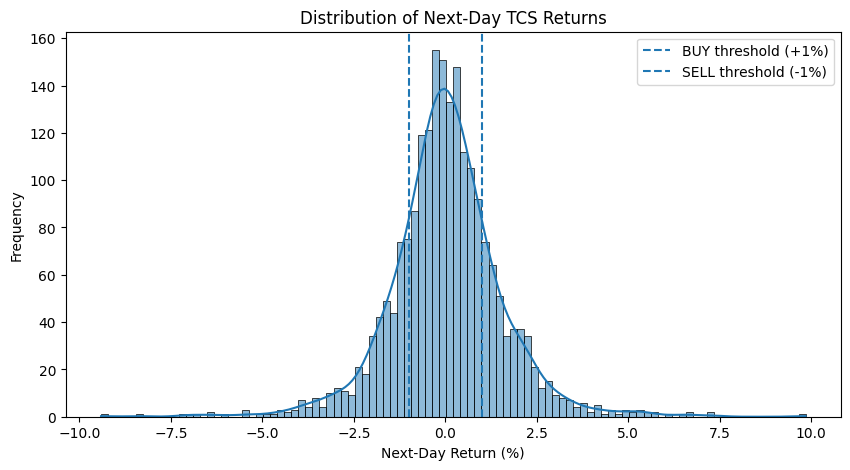

In [536]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    feature_df["Target_Return"].dropna(),
    bins=100,
    kde=True
)

plt.axvline(1, linestyle="--", label="BUY threshold (+1%)")
plt.axvline(-1, linestyle="--", label="SELL threshold (-1%)")

plt.title("Distribution of Next-Day TCS Returns")
plt.xlabel("Next-Day Return (%)")
plt.ylabel("Frequency")
plt.legend()
plt.show()

In [537]:
print("Rows before target cleanup:", len(feature_df))

print(
    "Missing Target_Price:",
    feature_df["Target_Price"].isna().sum()
)

print(
    "Missing Target_Return:",
    feature_df["Target_Return"].isna().sum()
)

Rows before target cleanup: 2112
Missing Target_Price: 1
Missing Target_Return: 1


In [538]:
print("Total columns:", len(feature_df.columns))

for i, col in enumerate(feature_df.columns, 1):
    print(i, col)

Total columns: 39
1 Date
2 Adj Close
3 Close
4 High
5 Low
6 Open
7 Volume
8 Daily_Return
9 Open_Close_Diff
10 High_Low_Diff
11 MA_10
12 MA_20
13 MA_50
14 RSI
15 MACD
16 MACD_Signal
17 BB_Middle
18 BB_Upper
19 BB_Lower
20 Volume_Change
21 Volume_MA
22 Close_Lag_1
23 Close_Lag_5
24 Close_Lag_10
25 Close_Lag_20
26 NIFTY_Close
27 NIFTY_Return
28 NIFTY_Volatility
29 News_Count
30 Avg_Sentiment
31 Positive_News
32 Negative_News
33 Neutral_News
34 CPI_Inflation
35 USD_INR
36 GDP_Growth
37 Target_Price
38 Target_Return
39 Target_Class


In [539]:
missing_report = pd.DataFrame({
    "Missing_Count": feature_df.isna().sum(),
    "Missing_Percentage": (
        feature_df.isna().mean() * 100
    ).round(2)
})

missing_report = missing_report[
    missing_report["Missing_Count"] > 0
].sort_values(
    "Missing_Count",
    ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percentage
USD_INR,2112,100.00
GDP_Growth,11,0.52
Target_Price,1,0.05
Target_Return,1,0.05


In [540]:
feature_columns = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",

    "Daily_Return",
    "Open_Close_Diff",
    "High_Low_Diff",

    "MA_10",
    "MA_20",
    "MA_50",
    "RSI",
    "MACD",
    "MACD_Signal",

    "BB_Upper",
    "BB_Middle",
    "BB_Lower",

    "Volume_Change",
    "Volume_MA",

    "Close_Lag_1",
    "Close_Lag_5",
    "Close_Lag_10",
    "Close_Lag_20",

    "NIFTY_Close",
    "NIFTY_Return",
    "NIFTY_Volatility",

    "CPI_Inflation",
    "USD_INR",
    "GDP_Growth"
]

In [541]:
target_columns = [
    "Target_Price",
    "Target_Return",
    "Target_Class"
]

In [542]:

# Step 1: Check the current dataset before cleanup
print("feature_df shape:", feature_df.shape)
print("Date dtype:", feature_df["Date"].dtype)
print("Date missing:", feature_df["Date"].isna().sum())

# Step 2: Build the same ML dataset without dropping rows
ml_check = feature_df[
    ["Date"] + feature_columns + target_columns
].copy()

print("\nML dataset BEFORE dropna:", ml_check.shape)

# Step 3: Find columns that are completely empty
all_missing = ml_check.columns[
    ml_check.isna().all()
].tolist()

print("\nColumns with ALL values missing:")
print(all_missing)

# Step 4: Count missing values in every column
missing_report = (
    ml_check.isna()
    .sum()
    .sort_values(ascending=False)
)

print("\nMissing values by column:")
print(missing_report[missing_report > 0])

# Step 5: Check how many rows survive the cleanup
valid_rows = ml_check.dropna(
    subset=feature_columns + target_columns
)

print("\nRows before cleanup:", len(ml_check))
print("Rows after cleanup:", len(valid_rows))
print("Rows removed:", len(ml_check) - len(valid_rows))


feature_df shape: (2112, 39)
Date dtype: datetime64[ns]
Date missing: 0

ML dataset BEFORE dropna: (2112, 33)

Columns with ALL values missing:
['USD_INR']

Missing values by column:
USD_INR          2112
GDP_Growth         11
Target_Price        1
Target_Return       1
dtype: int64

Rows before cleanup: 2112
Rows after cleanup: 0
Rows removed: 2112


In [546]:

# ============================================
# FINAL ML DATASET: VALIDATION AND CLEANUP
# ============================================

import pandas as pd

# 1. Create dataset
ml_df = ml_check.copy()

print("Original ML dataset shape:", ml_df.shape)

# 2. Check for an empty dataset
if ml_df.empty:
    raise ValueError(
        "Dataset is already empty. Check earlier filtering or merges."
    )

# 3. Identify columns with all values missing
all_missing = ml_df.columns[
    ml_df.isna().all()
].tolist()

print("\nColumns completely missing:", all_missing)

# Stop if Date or target columns have no valid data
required = ["Date"] + target_columns

missing_required = [
    col for col in required
    if col in ml_df.columns and col in all_missing
]

if missing_required:
    raise ValueError(
        f"Required columns have no data: {missing_required}. "
        "Fix the source data before continuing."
    )

# 4. Drop completely empty feature columns only
drop_columns = [
    col for col in all_missing
    if col not in required
]

ml_df.drop(columns=drop_columns, inplace=True)

# 5. Check missing values before cleanup
print("\nMissing values per column:")
print(
    ml_df.isna().sum()
    .sort_values(ascending=False)
    .loc[lambda x: x > 0]
)

# 6. Convert Date and remove invalid dates
ml_df["Date"] = pd.to_datetime(
    ml_df["Date"], errors="coerce"
)

ml_df = ml_df.dropna(subset=["Date"]).copy()

# 7. Remove rows with missing target values
ml_df = ml_df.dropna(subset=target_columns).copy()

# 8. Identify features still available
active_features = [
    col for col in feature_columns
    if col in ml_df.columns
]

# Stop if a feature is entirely missing
all_missing_features = [
    col for col in active_features
    if ml_df[col].isna().all()
]

if all_missing_features:
    raise ValueError(
        f"Features contain no valid data: {all_missing_features}"
    )

# 9. Remove rows with missing feature values
ml_df = ml_df.dropna(
    subset=active_features
).copy()

# 10. Sort dates and remove duplicate dates
ml_df = (
    ml_df.sort_values("Date")
    .drop_duplicates(subset=["Date"], keep="last")
    .reset_index(drop=True)
)

# 11. Final dataset report
print("\n========== FINAL ML DATASET ==========")
print("Dataset shape:", ml_df.shape)

if not ml_df.empty:
    print("Date range:")
    print(ml_df["Date"].min(), "to", ml_df["Date"].max())

    print("Missing values:", ml_df.isna().sum().sum())
    print("Duplicate rows:", ml_df.duplicated().sum())
    print("Duplicate dates:", ml_df["Date"].duplicated().sum())

    print("\nFinal columns:")
    print(ml_df.columns.tolist())

    display(ml_df.head())

else:
    raise ValueError(
        "All records were removed. Investigate missing values "
        "in the source features and target columns."
    )


Original ML dataset shape: (2112, 33)

Columns completely missing: ['USD_INR']

Missing values per column:
GDP_Growth       11
Target_Price      1
Target_Return     1
dtype: int64

========== FINAL ML DATASET ==========
Dataset shape: (2100, 32)
Date range:
2018-04-02 00:00:00 to 2026-09-29 00:00:00
Missing values: 0
Duplicate rows: 0
Duplicate dates: 0

Final columns:
['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Daily_Return', 'Open_Close_Diff', 'High_Low_Diff', 'MA_10', 'MA_20', 'MA_50', 'RSI', 'MACD', 'MACD_Signal', 'BB_Upper', 'BB_Middle', 'BB_Lower', 'Volume_Change', 'Volume_MA', 'Close_Lag_1', 'Close_Lag_5', 'Close_Lag_10', 'Close_Lag_20', 'NIFTY_Close', 'NIFTY_Return', 'NIFTY_Volatility', 'CPI_Inflation', 'GDP_Growth', 'Target_Price', 'Target_Return', 'Target_Class']


,Date,Open,High,Low,Close,Volume,Daily_Return,Open_Close_Diff,High_Low_Diff,MA_10,...,Close_Lag_10,Close_Lag_20,NIFTY_Close,NIFTY_Return,NIFTY_Volatility,CPI_Inflation,GDP_Growth,Target_Price,Target_Return,Target_Class
0,2018-04-02,1420.000000,1457.000000,1420.000000,1454.824951,1662988,2.123440,34.824951,37.000000,1422.564990,...,1434.849976,1517.525024,10211.799805,0.969968,0.916421,4.58,6.795384,1455.625000,0.054993,HOLD
1,2018-04-03,1446.050049,1464.949951,1446.050049,1455.625000,1937290,0.054993,9.574951,18.899902,1426.842493,...,1412.849976,1518.849976,10245.000000,0.325116,0.920673,4.58,6.795384,1455.449951,-0.012026,HOLD
2,2018-04-04,1464.724976,1467.000000,1446.000000,1455.449951,2841820,-0.012026,-9.275024,21.000000,1430.837488,...,1415.500000,1552.925049,10128.400391,-1.138112,0.930665,4.58,6.795384,1478.974976,1.616340,BUY
3,2018-04-05,1463.275024,1481.875000,1460.175049,1478.974976,1809424,1.616340,15.699951,21.699951,1435.492480,...,1432.425049,1521.400024,10325.150391,1.942557,1.008139,4.58,6.795384,1475.150024,-0.258622,HOLD
4,2018-04-06,1477.000000,1480.000000,1463.275024,1475.150024,1129018,-0.258622,-1.849976,16.724976,1440.169983,...,1428.375000,1513.724976,10331.599609,0.062461,0.982018,4.58,6.795384,1461.949951,-0.894829,HOLD


In [548]:

# Download / save the final ML dataset as CSV

import os

final_path = "/content/stock_prediction/data/processed/TCS_Final_ML_Dataset.csv"

# Save dataset in your current working directory
ml_df.to_csv(final_path, index=False)

print("Dataset saved successfully!")
print("File path:", os.path.abspath(final_path))
print("Dataset shape:", ml_df.shape)


Dataset saved successfully!
File path: /content/stock_prediction/data/processed/TCS_Final_ML_Dataset.csv
Dataset shape: (2100, 32)
